Task 1.4

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1) Детектор и ФЭУ
class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.fmt_positions = self.generate_fmts()

    def generate_fmts(self):
        phi = np.random.uniform(0, 2 * np.pi, self.N)
        U = np.random.uniform(-1, 1, self.N)
        sin_theta = np.sqrt(1 - U**2)

        x = self.R * sin_theta * np.cos(phi)
        y = self.R * sin_theta * np.sin(phi)
        z = self.R * U

        return np.column_stack([x, y, z])

    def count_hits(self, pos, directions):
        b = np.dot(directions, pos)
        c = np.dot(pos, pos) - self.R**2
        L = -b + np.sqrt(b**2 - c)
        points = pos + L[:, None] * directions

        # расстояния от точек на сфере до ФЭУ
        d_sq = 2 * self.R**2 - 2 * (points @ self.fmt_positions.T)
        N_hit = np.sum(np.min(d_sq, axis=1) <= self.r**2)

        return int(N_hit)

In [3]:
# 2) Источник и генерация направлений
class Source:
    def __init__(self, Y=10000, pos=(0.0, 0.0, 0.0)):
        self.Y = Y
        self.pos = np.array(pos, dtype=float)

    def generate_directions(self, E):
        N = int(self.Y * E)

        phi = np.random.uniform(0, 2 * np.pi, N)
        U = np.random.uniform(-1, 1, N)
        sin_theta = np.sqrt(1 - U**2)

        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = U

        return np.column_stack([x, y, z])

In [4]:
# 3) Моделирование одного события
def simulate_event(det, source, E):
    directions = source.generate_directions(E)
    N_hit = det.count_hits(source.pos, directions)
    Q = np.random.poisson(N_hit * det.a)
    return Q

In [5]:
# 4) Параметры
R = 2.0
N = 40
r = 0.1
a = 0.5
Y = 10000
E = 1.0
N_events = 1000

det = Detector(R, N, r, a)
source = Source(Y, pos=(0.0, 0.0, 0.0))

In [6]:
# 5) Моделирование 1000 событий при 1 МэВ
Q_events = np.zeros(N_events, dtype=int)

for i in range(N_events):
    Q_events[i] = simulate_event(det, source, E)

In [7]:
# 6) Средний заряд и относительная ширина
Q_mean = np.mean(Q_events)
Q_std = np.std(Q_events)
width_rel = Q_std / Q_mean

print(f"Средний заряд <Q>: {Q_mean:.2f}")
print(f"Стандартное отклонение: {Q_std:.2f}")
print(f"Относительная ширина: {width_rel:.4f}")

Средний заряд <Q>: 123.85
Стандартное отклонение: 13.06
Относительная ширина: 0.1055


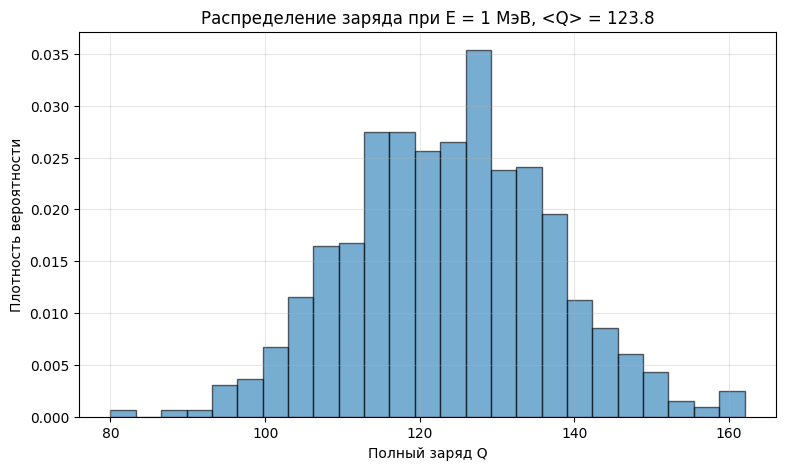

In [8]:
# 7) Распределение полного заряда
plt.figure(figsize=(9, 5))
plt.hist(Q_events, bins=25, density=True, alpha=0.6, edgecolor='black')
plt.xlabel('Полный заряд Q')
plt.ylabel('Плотность вероятности')
plt.title(f'Распределение заряда при E = 1 МэВ, <Q> = {Q_mean:.1f}')
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# 8) Относительная ширина при разных энергиях
E_vals = np.array([0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0])
Q_mean_E = np.zeros(len(E_vals))
width_rel_E = np.zeros(len(E_vals))

for j, E in enumerate(E_vals):
    Q = np.zeros(N_events, dtype=int)
    for i in range(N_events):
        Q[i] = simulate_event(det, source, E)

    Q_mean_E[j] = np.mean(Q)
    width_rel_E[j] = np.std(Q) / Q_mean_E[j]
    print(f"E = {E:.1f} МэВ: <Q> = {Q_mean_E[j]:.2f}, sigma_Q/<Q> = {width_rel_E[j]:.4f}")

E = 0.2 МэВ: <Q> = 24.84, sigma_Q/<Q> = 0.2405
E = 0.5 МэВ: <Q> = 61.53, sigma_Q/<Q> = 0.1559
E = 0.7 МэВ: <Q> = 85.46, sigma_Q/<Q> = 0.1350
E = 1.0 МэВ: <Q> = 123.11, sigma_Q/<Q> = 0.1095
E = 1.5 МэВ: <Q> = 184.32, sigma_Q/<Q> = 0.0915
E = 2.0 МэВ: <Q> = 245.99, sigma_Q/<Q> = 0.0782
E = 3.0 МэВ: <Q> = 368.48, sigma_Q/<Q> = 0.0617


E = 0.5 МэВ: <Q> = 62.51, sigma_Q/<Q> = 0.1550


E = 0.7 МэВ: <Q> = 87.31, sigma_Q/<Q> = 0.1261


E = 1.0 МэВ: <Q> = 125.15, sigma_Q/<Q> = 0.1111


E = 1.5 МэВ: <Q> = 187.47, sigma_Q/<Q> = 0.0892


E = 2.0 МэВ: <Q> = 249.26, sigma_Q/<Q> = 0.0780


E = 3.0 МэВ: <Q> = 375.05, sigma_Q/<Q> = 0.0648


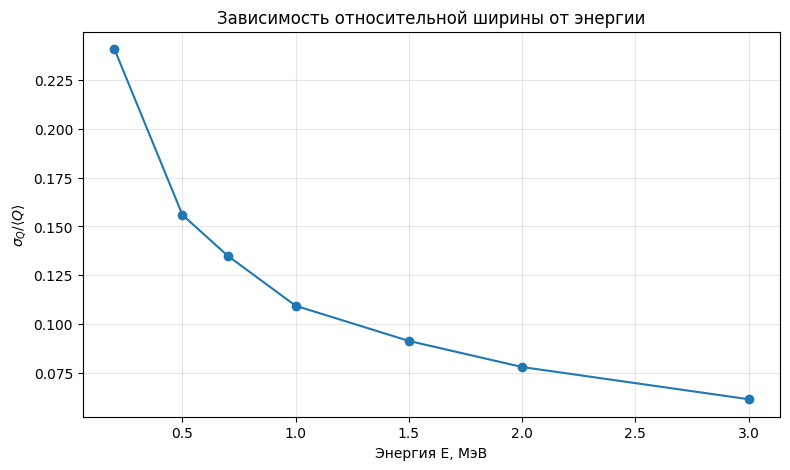

In [10]:
# 9) Зависимость относительной ширины от энергии
plt.figure(figsize=(9, 5))
plt.plot(E_vals, width_rel_E, 'o-')
plt.xlabel('Энергия E, МэВ')
plt.ylabel(r'$\sigma_Q / \langle Q \rangle$')
plt.title('Зависимость относительной ширины от энергии')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
# 10) Источник со сдвигом на 1 м по оси z
source_shift = Source(Y, pos=(0.0, 0.0, 1.0))
Q_shift = np.zeros(N_events, dtype=int)

for i in range(N_events):
    Q_shift[i] = simulate_event(det, source_shift, 1.0)

In [12]:
# 11) Сравнение среднего заряда
Q_mean_shift = np.mean(Q_shift)
delta_Q = (Q_mean_shift - Q_mean) / Q_mean

print(f"Средний заряд в центре: {Q_mean:.2f}")
print(f"Средний заряд при z = 1 м: {Q_mean_shift:.2f}")
print(f"Относительное изменение: {delta_Q * 100:.2f}%")

Средний заряд в центре: 123.85
Средний заряд при z = 1 м: 132.54
Относительное изменение: 7.02%
